<a href="https://colab.research.google.com/github/raghav-garg8/Electricity-Demand-Forecasting-using-LSTM/blob/main/Electricity_Demand_Forcast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from keras.losses import MeanSquaredError

import os
import joblib
import warnings
warnings.filterwarnings("ignore")

In [ ]:
path = kagglehub.dataset_download("pratikyuvrajchougule/delhi-datset")
print("Path to dataset files:", path)

100%|██████████| 439k/439k [00:00<00:00, 602kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/pratikyuvrajchougule/delhi-datset/versions/1


In [ ]:
files_in_path = os.listdir(path)
print("Files in downloaded directory:", files_in_path)

csv_file = [f for f in files_in_path if f.endswith('.csv')][0]
full_csv_path = os.path.join(path, csv_file)

df = pd.read_csv(full_csv_path)
print(df.head())
print(df.columns)

Files in downloaded directory: ['delhi_power_load_dataset1.csv']
         Date      Time  Temperature (°C)  Humidity (%)  Wind Speed (km/h)  \
0  2023-01-01  00:00:00          6.044387     52.181561          15.276358   
1  2023-01-01  01:00:00         18.036797     85.355874           3.099857   
2  2023-01-01  02:00:00         44.056775     81.505825           6.165830   
3  2023-01-01  03:00:00          8.404040     49.434816          10.242513   
4  2023-01-01  04:00:00          8.100872     82.831944           2.102916   

   Rain (mm)  Public Holiday  Weekly Holiday  Festival  \
0  19.840317               0               1         0   
1  11.540988               0               1         0   
2   0.000000               0               1         0   
3  19.077343               0               1         0   
4   0.000000               0               1         0   

  Real Estate Development  Low Development Area (%)  \
0                    High                 39.917808   
1      

In [ ]:
if 'Datetime' in df.columns:
    df['Datetime'] = pd.to_datetime(df['Datetime'])
elif {'Date', 'Time'}.issubset(df.columns):
    df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
else:
    raise ValueError("No suitable datetime columns found. Please check column names.")

df = df.sort_values('Datetime')
df.set_index('Datetime', inplace=True)

print(df.index.min(), df.index.max())
print(df.info())

2023-01-01 00:00:00 2023-12-31 00:00:00
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8737 entries, 2023-01-01 00:00:00 to 2023-12-31 00:00:00
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Date                         8737 non-null   object 
 1   Time                         8737 non-null   object 
 2   Temperature (°C)             8737 non-null   float64
 3   Humidity (%)                 8737 non-null   float64
 4   Wind Speed (km/h)            8737 non-null   float64
 5   Rain (mm)                    8737 non-null   float64
 6   Public Holiday               8737 non-null   int64  
 7   Weekly Holiday               8737 non-null   int64  
 8   Festival                     8737 non-null   int64  
 9   Real Estate Development      8737 non-null   object 
 10  Low Development Area (%)     8737 non-null   float64
 11  Medium Development Area (%)  8737 non-null   float64
 12  

In [ ]:
print(df.isna().sum())

Date                           0
Time                           0
Temperature (°C)               0
Humidity (%)                   0
Wind Speed (km/h)              0
Rain (mm)                      0
Public Holiday                 0
Weekly Holiday                 0
Festival                       0
Real Estate Development        0
Low Development Area (%)       0
Medium Development Area (%)    0
High Development Area (%)      0
Load (MW)                      0
dtype: int64


In [ ]:
TARGET_COL = 'Load (MW)'
TEMP_COL   = 'Temperature (°C)'
HUMID_COL  = 'Humidity (%)'
WIND_COL   = 'Wind Speed (km/h)'
RAIN_COL   = 'Rain (mm)'

rename_map = {}
if TARGET_COL in df.columns:
    rename_map[TARGET_COL] = 'load'
else:
    raise ValueError("Please set TARGET_COL to the correct demand column name.")

if TEMP_COL in df.columns:
  rename_map[TEMP_COL]  = 'temp'

if HUMID_COL in df.columns:
  rename_map[HUMID_COL] = 'humidity'

if WIND_COL in df.columns:
  rename_map[WIND_COL]  = 'wind_speed'

if RAIN_COL in df.columns:
  rename_map[RAIN_COL]  = 'rainfall'

df = df.rename(columns=rename_map)
print(df.columns)

Index(['Date', 'Time', 'temp', 'humidity', 'wind_speed', 'rainfall',
       'Public Holiday', 'Weekly Holiday', 'Festival',
       'Real Estate Development', 'Low Development Area (%)',
       'Medium Development Area (%)', 'High Development Area (%)', 'load'],
      dtype='object')


In [ ]:
df['load'] = df['load'].replace(2000, np.nan)
df['load'] = df['load'].interpolate(method='time')

# OPTIONAL: smoothing
df['load'] = df['load'].rolling(window=3, min_periods=1).mean()

df = df.dropna()

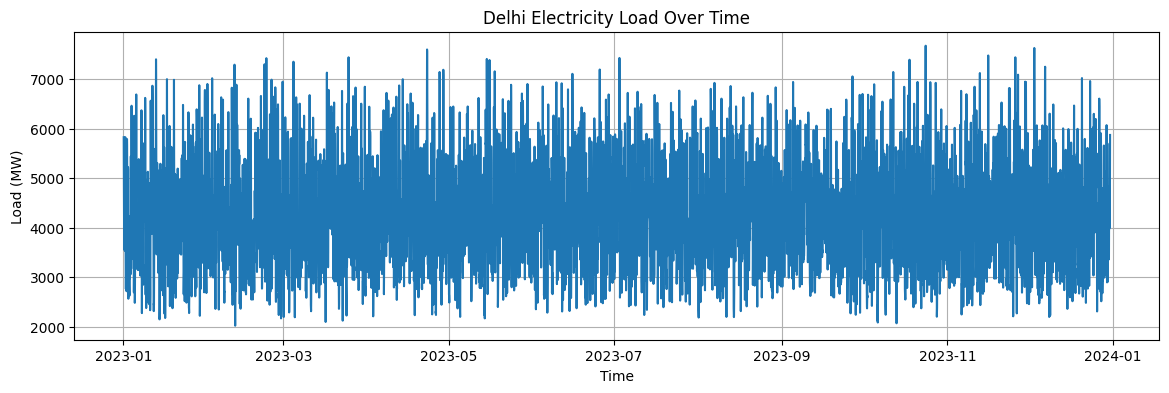

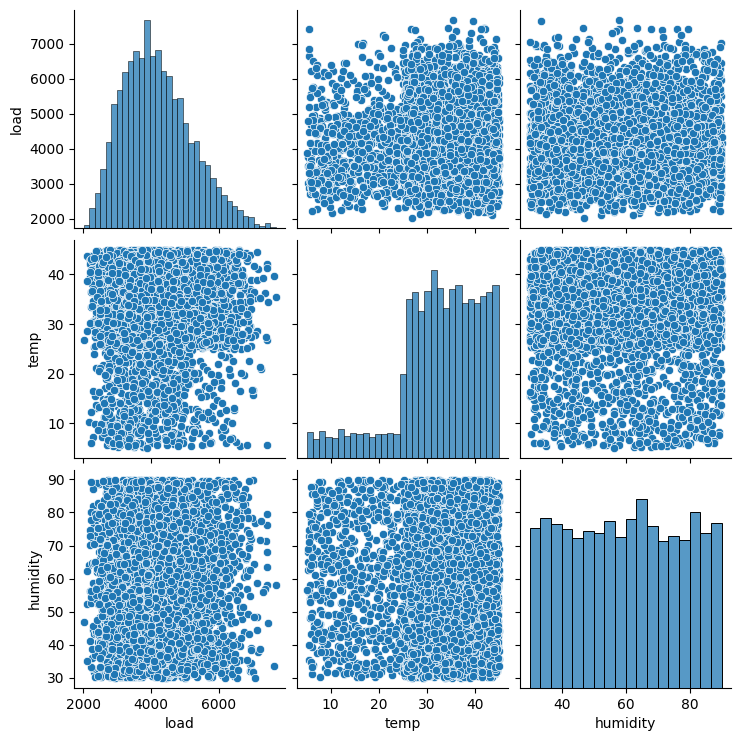

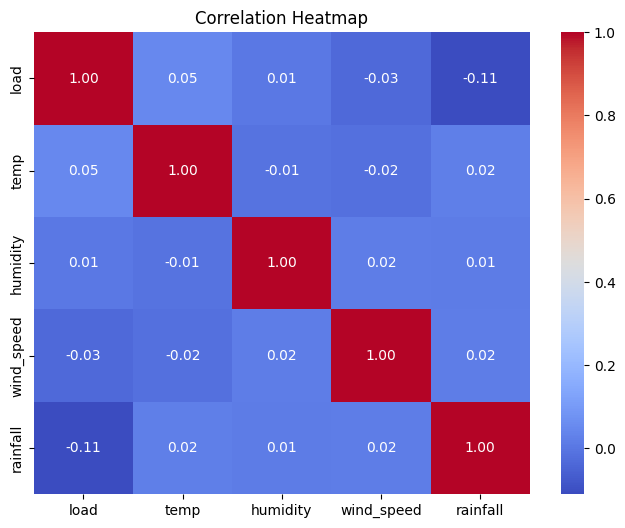

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(df['load'])
plt.title('Delhi Electricity Load Over Time')
plt.xlabel('Time')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.show()

sample = df[['load', 'temp', 'humidity']].dropna().sample(min(5000, len(df)))
sns.pairplot(sample)
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[['load', 'temp', 'humidity', 'wind_speed', 'rainfall']].corr(),
            annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
fe_df = df.copy()

fe_df['hour'] = fe_df.index.hour
fe_df['dayofweek'] = fe_df.index.dayofweek  # Monday=0
fe_df['month'] = fe_df.index.month
fe_df['is_weekend'] = fe_df['dayofweek'].isin([5, 6]).astype(int)

fe_df['hour_sin'] = np.sin(2 * np.pi * fe_df['hour'] / 24)
fe_df['hour_cos'] = np.cos(2 * np.pi * fe_df['hour'] / 24)

fe_df['dow_sin'] = np.sin(2 * np.pi * fe_df['dayofweek'] / 7)
fe_df['dow_cos'] = np.cos(2 * np.pi * fe_df['dayofweek'] / 7)

for lag in [1, 24]:
    fe_df[f'load_lag_{lag}'] = fe_df['load'].shift(lag)

fe_df['load_rolling_24h'] = fe_df['load'].rolling(window=24).mean()

fe_df = fe_df.dropna()
print(fe_df.head())


                           Date      Time       temp   humidity  wind_speed  \
Datetime                                                                      
2023-01-02 02:00:00  2023-01-02  02:00:00  43.345398  38.677139   18.923402   
2023-01-02 03:00:00  2023-01-02  03:00:00  15.034565  49.563476    3.917608   
2023-01-02 04:00:00  2023-01-02  04:00:00  23.057914  87.208495   10.535580   
2023-01-02 05:00:00  2023-01-02  05:00:00  23.599569  36.871870   11.285370   
2023-01-02 06:00:00  2023-01-02  06:00:00  38.441835  38.307609    4.110861   

                      rainfall  Public Holiday  Weekly Holiday  Festival  \
Datetime                                                                   
2023-01-02 02:00:00   5.742739               0               0         0   
2023-01-02 03:00:00  15.652186               0               0         0   
2023-01-02 04:00:00  13.926697               0               0         0   
2023-01-02 05:00:00  10.644343               0               0    

In [ ]:
feature_cols = [
    'load',
    'temp',
    'humidity',
    'wind_speed',
    'rainfall',
    'hour_sin', 'hour_cos',
    'dow_sin', 'dow_cos',
    'is_weekend',
    'load_lag_1',
    'load_lag_24',
    'load_rolling_24h'
]

feature_cols = [c for c in feature_cols if c in fe_df.columns]
print("Using features:", feature_cols)

data = fe_df[feature_cols].copy()

Using features: ['load', 'temp', 'humidity', 'wind_speed', 'rainfall', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'load_lag_1', 'load_lag_24', 'load_rolling_24h']


In [ ]:
split_ratio = 0.8
split_index = int(len(data) * split_ratio)

train = data.iloc[:split_index]
test  = data.iloc[split_index:]

print("Train shape:", train.shape)
print("Test shape:", test.shape)

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train)
test_scaled  = scaler.transform(test)

n_features = train.shape[1]
print("Number of features:", n_features)

Train shape: (6968, 13)
Test shape: (1743, 13)
Number of features: 13


In [ ]:
SEQ_LEN = 24

def create_sequences(data_scaled, seq_len, target_col_index=0):
    """
    data_scaled: 2D numpy array (time, features)
    Returns: X, y
        X shape: (samples, seq_len, features)
        y shape: (samples,)
    target_col_index: which column in data_scaled is the target (load)
    """
    X, y = [], []
    for i in range(seq_len, len(data_scaled)):
        X.append(data_scaled[i-seq_len:i, :])
        y.append(data_scaled[i, target_col_index])
    return np.array(X), np.array(y)

target_index = feature_cols.index('load')

X_train, y_train = create_sequences(train_scaled, SEQ_LEN, target_col_index=target_index)
X_test,  y_test  = create_sequences(test_scaled,  SEQ_LEN, target_col_index=target_index)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6944, 24, 13)
y_train shape: (6944,)
X_test shape: (1719, 24, 13)
y_test shape: (1719,)


In [ ]:
model = Sequential()
model.add(LSTM(64, return_sequences=True, input_shape=(SEQ_LEN, n_features)))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dropout(0.2))
model.add(Dense(16, activation='relu'))
model.add(Dense(1))  # predicting next-step load

model.compile(optimizer='adam', loss='mse')

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,929 (128.63 KB)

 Trainable params: 32,929 (128.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=64,
    callbacks=[es],
    verbose=1
)

Epoch 1/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.0432 - val_loss: 0.0305
Epoch 2/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0290 - val_loss: 0.0275
Epoch 3/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0270 - val_loss: 0.0252
Epoch 4/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - loss: 0.0263 - val_loss: 0.0236
Epoch 5/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0243 - val_loss: 0.0216
Epoch 6/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.0223 - val_loss: 0.0181
Epoch 7/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - loss: 0.0182 - val_loss: 0.0150
Epoch 8/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0152 - val_loss: 0.0139
Epoch 9/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - loss: 0.0141 - val_loss: 0.0123
Epoch 10/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - loss: 0.0125 - val_loss: 0.0110
Epoch 11/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.0114 - val_loss: 0.0110
Epoch 12/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.0

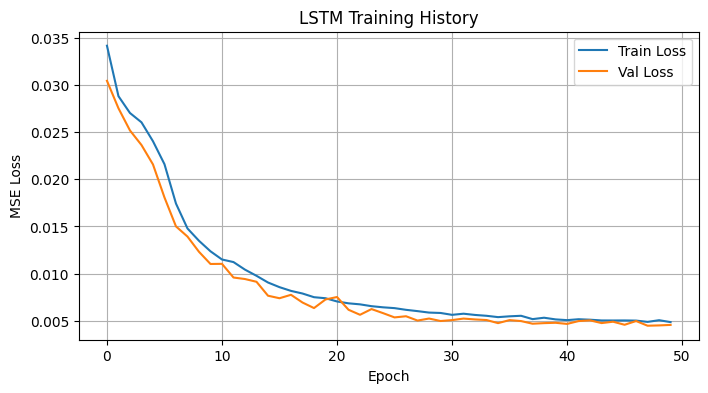

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('LSTM Training History')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_train_pred_scaled = model.predict(X_train)
y_test_pred_scaled  = model.predict(X_test)

def inverse_scale_load(y_scaled, scaler, n_features, target_index=0):
    """
    y_scaled: (n_samples, 1) or (n_samples,)
    Returns: y in original units for target (load)
    """
    y_scaled = np.array(y_scaled).reshape(-1, 1)
    # Create dummy array with same number of features
    dummy = np.zeros((len(y_scaled), n_features))
    dummy[:, target_index] = y_scaled[:, 0]
    inv = scaler.inverse_transform(dummy)
    return inv[:, target_index]

y_train_pred = inverse_scale_load(y_train_pred_scaled, scaler, n_features, target_index)
y_test_pred  = inverse_scale_load(y_test_pred_scaled,  scaler, n_features, target_index)

y_train_true = inverse_scale_load(y_train, scaler, n_features, target_index)
y_test_true  = inverse_scale_load(y_test,  scaler, n_features, target_index)

217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


In [ ]:
def evaluate(true, pred, label='Test'):
    mae = mean_absolute_error(true, pred)
    rmse = math.sqrt(mean_squared_error(true, pred))
    mape = np.mean(np.abs((true - pred) / true)) * 100
    print(f"{label} MAE : {mae:.3f}")
    print(f"{label} RMSE: {rmse:.3f}")
    print(f"{label} MAPE: {mape:.2f}%")

evaluate(y_train_true, y_train_pred, label='Train')
evaluate(y_test_true, y_test_pred, label='Test')

Train MAE : 281.056
Train RMSE: 347.684
Train MAPE: 7.04%
Test MAE : 287.507
Test RMSE: 360.501
Test MAPE: 7.22%


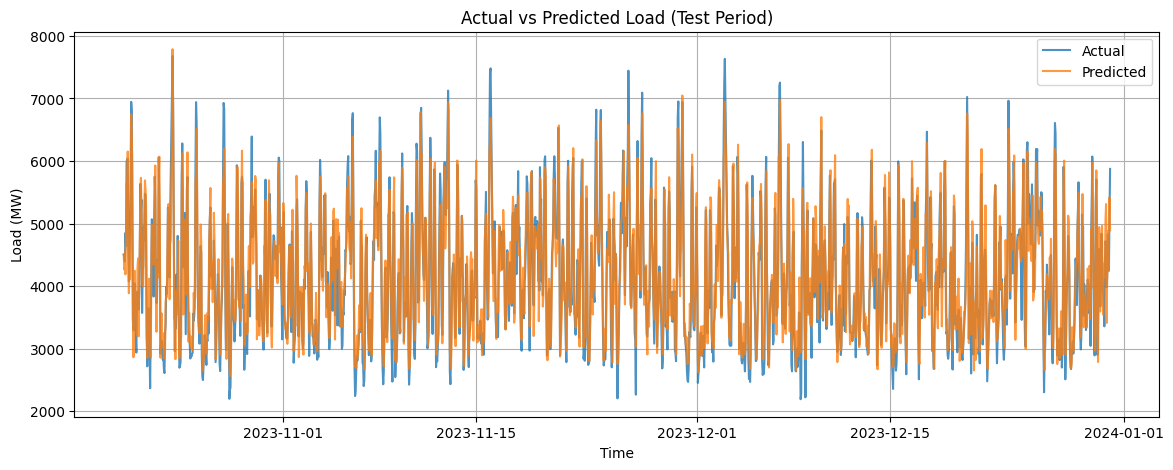

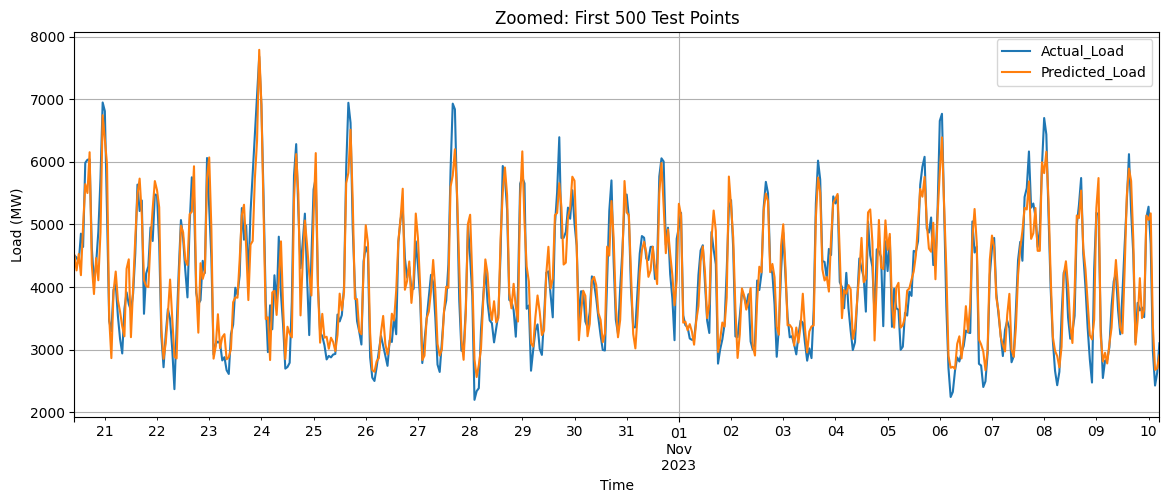

In [ ]:
test_index = fe_df.iloc[split_index:].index[SEQ_LEN:]  # because we lost first SEQ_LEN timesteps
test_plot_df = pd.DataFrame({
    'Datetime': test_index,
    'Actual_Load': y_test_true,
    'Predicted_Load': y_test_pred
}).set_index('Datetime')

plt.figure(figsize=(14, 5))
plt.plot(test_plot_df['Actual_Load'], label='Actual', alpha=0.8)
plt.plot(test_plot_df['Predicted_Load'], label='Predicted', alpha=0.8)
plt.title('Actual vs Predicted Load (Test Period)')
plt.xlabel('Time')
plt.ylabel('Load (MW)')
plt.legend()
plt.grid(True)
plt.show()

# Optional: zoom into a specific range
plt.figure(figsize=(14, 5))
test_plot_df.iloc[:500].plot(ax=plt.gca())
plt.title('Zoomed: First 500 Test Points')
plt.xlabel('Time')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.show()

In [ ]:
# Assuming these already exist from your previous work
# model       -> trained LSTM
# scaler      -> MinMaxScaler fitted on train data
# feature_cols -> list of feature names in the same order as used in training
# fe_df       -> feature-engineered dataframe with datetime index and 'load' column

model.save("lstm_delhi_load.h5")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(feature_cols, "feature_cols.pkl")
fe_df.to_csv("fe_df_processed.csv")

In [ ]:
model.compile(optimizer='adam', loss=MeanSquaredError())
model.save("lstm_delhi_load.keras")   # IMPORTANT: Use .keras, NOT .h5

In [ ]:
pip install streamlit

In [ ]:
!wget -q -O - ipv4.icanhazip.com

35.237.144.177


In [ ]:
!rm -r ~/.streamlit/

rm: cannot remove '/root/.streamlit/': No such file or directory


In [ ]:
!npm i localtunnel

⠙⠹⠸⠼⠴⠦⠧
up to date, audited 23 packages in 1s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧
2 high severity vulnerabilities

To address all issues (including breaking changes), run:
  npm audit fix --force

Run `npm audit` for details.
⠧

In [ ]:
!streamlit run app.py & npx localtunnel --port 8501

⠙

your url is: https://rich-kings-cover.loca.lt

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.144.177:8501

2025-11-29 12:33:46.399205: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764419626.446020   13517 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764419626.462177   13517 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1764419626.505803   13517 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1764419626.505990   13517 